<a href="https://colab.research.google.com/github/masumeaslanii/ML2026/blob/main/The_Third_Session_1D_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install mnist1d

In [2]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mnist1d.data import make_dataset, get_dataset_args
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import transforms, datasets

## How to create 1D CNN for training and testing on 1D MNIST:

* Preparing our dataset
* Designing 1D CNN
* Train and test loop
* Visualizing our loss and accuracy

\\[ (N, C, L) \\]

Where:

- \\(N\\): Number of samples in each batch
- \\(C\\): Number of input channels
- \\(L\\): Length of each signal


In [3]:
args = get_dataset_args()
data = make_dataset(args)

In [4]:
data

{'x': array([[-0.33200567, -0.47191037, -0.77869708, ..., -0.7167305 ,
         -0.96195825, -0.89016639],
        [ 1.96548088,  2.30021254,  2.21339278, ..., -1.68751297,
         -1.42642212, -1.36421511],
        [-0.01930303,  0.07863308,  0.62488909, ..., -1.08555748,
         -1.79809121, -2.3153282 ],
        ...,
        [-1.69449348, -1.2805858 , -0.65125255, ..., -0.72365942,
         -0.38266551, -0.03165042],
        [ 0.99646721,  0.80844603,  0.1553411 , ..., -0.30286571,
         -0.28555128, -0.1183879 ],
        [-0.6939948 , -0.27532169,  0.29267968, ..., -1.21624513,
         -1.4649417 , -1.65099286]]),
 'x_test': array([[-0.07877078, -0.21073171, -0.09175138, ...,  1.13416264,
          0.84632982,  0.34613289],
        [ 0.47104725,  0.73107223,  0.78374075, ..., -0.46250157,
         -0.18451044,  0.09676974],
        [ 1.7738889 ,  1.26898205,  1.37670332, ..., -0.70019867,
         -0.10291667,  0.07403612],
        ...,
        [-0.6091856 , -0.11078297,  0.2

In [5]:
print(type(data))
print(data.keys() if isinstance(data, dict) else data)

<class 'dict'>
dict_keys(['x', 'x_test', 'y', 'y_test', 't', 'templates'])


In [6]:
Xtrain = data['x']
ytrain = data['y']

Xtest = data['x_test']
ytest = data['y_test']

In [7]:
type(Xtrain), Xtrain.dtype, ytrain.dtype

(numpy.ndarray, dtype('float64'), dtype('int64'))

In [8]:
X_train = torch.tensor(Xtrain, dtype= torch.float32)
y_train = torch.tensor(ytrain, dtype= torch.long)

X_test = torch.tensor(Xtest, dtype= torch.float32)
y_test = torch.tensor(ytest, dtype= torch.long)

In [9]:
X_train.shape, y_train.shape

(torch.Size([4000, 40]), torch.Size([4000]))

`unsqueeze(1)` adds a new dimension at index 1, changing the shape from `(4000, 40)` to `(4000, 1, 40)` to match the required `(N, C, L)` input format of `Conv1d`.

In [10]:
X_train = X_train.unsqueeze(1)
X_test = X_test.unsqueeze(1)

In [11]:
X_train.shape

torch.Size([4000, 1, 40])

`TensorDataset` pairs each input sample with its corresponding label to create the training and test datasets.

In [12]:
Tensortrain = TensorDataset(X_train, y_train)
Tensortest = TensorDataset(X_test, y_test)

`DataLoader` divides the dataset into batches of 64 samples and optionally shuffles their order during each iteration.

In [13]:
Trainloader = DataLoader(Tensortrain, batch_size= 64, shuffle= True)
Testloader = DataLoader(Tensortest, batch_size= 64, shuffle= True)

# Designing 1D CNN

### Shape Changes Through the 1D CNN

The input tensor has shape **`(N, C, L)`**, where:
- `N`: batch size
- `C`: number of channels
- `L`: sequence length

For an input shape of `(64, 1, 40)`, the dimensions change as follows:

| Layer | Output Shape `(N, C, L)` | Explanation |
|---|---|---|
| Input | `(64, 1, 40)` | 1 input channel and sequence length 40 |
| `Conv1d(1, 16, kernel_size=3, padding=1, stride=1)` | `(64, 16, 40)` | Channels increase from 1 to 16; length stays the same |
| `BatchNorm1d(16)` | `(64, 16, 40)` | Shape remains unchanged |
| `ReLU()` | `(64, 16, 40)` | Shape remains unchanged |
| `MaxPool1d(kernel_size=2, stride=2)` | `(64, 16, 20)` | Sequence length is halved |
| `Conv1d(16, 32, kernel_size=3, padding=1, stride=1)` | `(64, 32, 20)` | Channels increase from 16 to 32 |
| `BatchNorm1d(32)` | `(64, 32, 20)` | Shape remains unchanged |
| `ReLU()` | `(64, 32, 20)` | Shape remains unchanged |
| `MaxPool1d(kernel_size=2, stride=2)` | `(64, 32, 10)` | Sequence length is halved |
| `Conv1d(32, 64, kernel_size=3, padding=1, stride=1)` | `(64, 64, 10)` | Channels increase from 32 to 64 |
| `BatchNorm1d(64)` | `(64, 64, 10)` | Shape remains unchanged |
| `ReLU()` | `(64, 64, 10)` | Shape remains unchanged |
| `AdaptiveAvgPool1d(1)` | `(64, 64, 1)` | Each channel is reduced to a single value |

**Key idea:** Convolutional layers change the number of channels, pooling layers reduce the sequence length, and Batch Normalization and ReLU preserve the tensor shape.

### Shape Changes in the Fully Connected (FC) Layers

After the convolutional blocks, the tensor has shape `(N, 64, 1)`, where `N` is the batch size.

| Layer | Output Shape `(N, Features)` | Explanation |
|---|---|---|
| `AdaptiveAvgPool1d(1)` | `(64, 64, 1)` | Reduces the sequence length to 1 for each channel |
| `Flatten()` | `(64, 64)` | Converts the tensor into a 2D tensor by removing the last two dimensions into a single feature dimension |
| `Linear(64, 128)` | `(64, 128)` | Maps 64 input features to 128 output features |
| `ReLU()` | `(64, 128)` | Applies the activation function without changing the shape |
| `Dropout(p=0.2)` | `(64, 128)` | Randomly sets 20% of activations to zero during training |
| `Linear(128, num_classes)` | `(64, num_classes)` | Produces one logit for each class |

**Key idea:** The fully connected layers transform the extracted features into class scores. The final output has shape `(N, num_classes)`, where each row contains the logits for one sample.

In [14]:
class CNN1D(nn.Module):
  def __init__(self, in_channel, num_classes):

    super(CNN1D, self).__init__()
    # or `super().__init__()`

    self.Blocks = nn.Sequential(nn.Conv1d(in_channels= in_channel, out_channels= 16, kernel_size= 3, padding= 1, stride= 1),
                                nn.BatchNorm1d(num_features= 16),
                                nn.ReLU(),
                                nn.MaxPool1d(kernel_size= 2, stride= 2),


                                nn.Conv1d(in_channels= 16, out_channels= 32, kernel_size= 3, padding= 1, stride= 1),
                                nn.BatchNorm1d(num_features= 32),
                                nn.ReLU(),
                                nn.MaxPool1d(kernel_size= 2, stride= 2),


                                nn.Conv1d(in_channels= 32, out_channels= 64, kernel_size= 3, padding= 1, stride= 1),
                                nn.BatchNorm1d(num_features= 64),
                                nn.ReLU(),
                                nn.AdaptiveAvgPool1d(output_size= 1))

    self.FC = nn.Sequential(nn.Flatten(),
                            nn.Linear(64*1, 128),
                            nn.ReLU(),
                            nn.Dropout(p= 0.2),
                            nn.Linear(128, num_classes))


  def forward(self, x):
    x = self.Blocks(x)
    x = self.FC(x)

    return x

In [15]:
torch.manual_seed(42)

CNN_Model = CNN1D(1, 10)
CNN_Model

CNN1D(
  (Blocks): Sequential(
    (0): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (FC): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias

`CNN_Model.state_dict()` returns a dictionary containing the model's learnable parameters and other state variables, such as weights, biases, and Batch Normalization statistics.

In [16]:
CNN_Model.state_dict()

OrderedDict([('Blocks.0.weight',
              tensor([[[ 0.4414,  0.4792, -0.1353]],
              
                      [[ 0.5304, -0.1265,  0.1165]],
              
                      [[-0.2811,  0.3391,  0.5090]],
              
                      [[-0.4236,  0.5018,  0.1081]],
              
                      [[ 0.4266,  0.0782,  0.2784]],
              
                      [[-0.0815,  0.4451,  0.0853]],
              
                      [[-0.2695,  0.1472, -0.2660]],
              
                      [[-0.0677, -0.2345,  0.3830]],
              
                      [[-0.4557, -0.2662, -0.1630]],
              
                      [[-0.3471,  0.0545, -0.5702]],
              
                      [[ 0.5214, -0.4904,  0.4457]],
              
                      [[ 0.0961, -0.1875,  0.3568]],
              
                      [[ 0.0900,  0.4665,  0.0631]],
              
                      [[-0.1821,  0.1551, -0.1566]],
              
               

## How to compute the number of model's parameters?

Calculates the total number of learnable parameters (weights and biases) in the model by summing the number of elements in each parameter tensor.

In [17]:
Total_para = sum(p.numel() for p in CNN_Model.parameters())
Total_para

17674

## Setup loss and optimizer

- `nn.CrossEntropyLoss()` measures the difference between the model's predicted logits and the true class labels.
- `optim.SGD(CNN_Model.parameters(), lr=0.001)` initializes the Stochastic Gradient Descent optimizer to update the model's parameters using a learning rate of 0.001.

In [18]:
loss = nn.CrossEntropyLoss()
optimizer = optim.SGD(CNN_Model.parameters(), lr= 0.001)

🈁
## Train and Test Loop

`start_time = time.time()`: Records the start time to measure the program's execution time.


In [19]:
start_time = time.time()

torch.manual_seed(42)

epochs = 500

 Creating empty lists to store the numbers

In [20]:
epoch_list = []
tr_loss_list = []
tr_acc_list = []
te_loss_list = []
te_acc_list = []

### 1. Training Loop
- `for epoch in range(epochs)`: Repeats the training process for the specified number of epochs.
- `CNN_Model.train()`: Sets the model to training mode.
- `train_loss = 0`: Initializes the total training loss.
- `train_correct = 0`: Initializes the number of correctly predicted training samples.
- `train_total = 0`: Initializes the total number of training samples processed.

### 2. Forward Pass
- `for x, y in Trainloader`: Iterates through the training data in batches.
- `tr_out = CNN_Model(x)`: Passes the input data through the CNN model to obtain predictions.
- `_, tr_pre = torch.max(tr_out, dim=1)`: Finds the predicted class with the highest output score for each sample.
- `trainloss = loss(tr_out, y)`: Calculates the loss by comparing the predictions with the true labels.

### 3. Backward Pass
- `optimizer.zero_grad()`: Clears the gradients from the previous iteration.
- `trainloss.backward()`: Calculates the gradients of the loss with respect to the model parameters.
- `optimizer.step()`: Updates the model parameters using the calculated gradients.

### 4. Training Metrics
- `train_loss += trainloss.item()`: Adds the current batch loss to the total training loss.
- `train_total += tr_out.size(0)`: Updates the total number of training samples processed.
- `train_correct += (tr_pre == y).sum().item()`: Counts the correctly classified samples in the current batch.
- `train_accuracy = (train_correct / train_total) * 100`: Calculates the training accuracy as a percentage.

### 5. Model Evaluation
- `CNN_Model.eval()`: Sets the model to evaluation mode.
- `test_loss = 0`: Initializes the total test loss.
- `test_correct = 0`: Initializes the number of correctly predicted test samples.
- `test_total = 0`: Initializes the total number of test samples processed.
- `with torch.inference_mode()`: Disables gradient calculations during evaluation.
- `for i, j in Testloader`: Iterates through the test data in batches.
- `te_out = CNN_Model(i)`: Passes the test inputs through the model to obtain predictions.
- `testloss = loss(te_out, j)`: Calculates the test loss for the current batch.
- `__, te_pre = torch.max(te_out, dim=1)`: Finds the predicted class for each test sample.
- `test_loss += testloss.item()`: Adds the current batch loss to the total test loss.
- `test_total += te_out.size(0)`: Updates the total number of test samples processed.
- `test_correct += (te_pre == j).sum().item()`: Counts the correctly classified test samples.
- `test_accuracy = 100 * (test_correct / test_total)`: Calculates the test accuracy as a percentage.

### 6. Storing and Displaying Results
- `if (epoch + 1) % 100 == 0`: Executes the following code every 100 epochs.
- `epoch_list.append(epoch + 1)`: Stores the current epoch number.
- `tr_loss_list.append(train_loss)`: Stores the total training loss.
- `tr_acc_list.append(train_accuracy)`: Stores the training accuracy.
- `te_loss_list.append(test_loss)`: Stores the total test loss.
- `te_acc_list.append(test_accuracy)`: Stores the test accuracy.
- `print(...)`: Displays the epoch number, training loss, test loss, and accuracy values.

**Note:** The training and test losses are sums of batch losses, not averages.

In [21]:
for epoch in range(epochs):

  CNN_Model.train()

  train_loss = 0
  train_correct = 0
  train_total = 0

    # Forward pass
  for x, y in Trainloader:

    tr_out = CNN_Model(x)


    _, tr_pre = torch.max(tr_out, dim= 1)


    trainloss = loss(tr_out, y)



    # Backward pass

    optimizer.zero_grad()
    trainloss.backward()
    optimizer.step()


    train_loss += trainloss.item()

    train_total += tr_out.size(0)

    train_correct += (tr_pre == y).sum().item()


  train_accuracy = (train_correct/train_total) * 100



  CNN_Model.eval()

  test_loss = 0
  test_correct = 0
  test_total = 0

  with torch.inference_mode():

    for i, j in Testloader:

      te_out = CNN_Model(i)
      testloss = loss(te_out, j)

      __, te_pre = torch.max(te_out, dim= 1)

      test_loss += testloss.item()

      test_total += te_out.size(0)

      test_correct += (te_pre == j).sum().item()

  test_accuracy = 100 * (test_correct/test_total)

  if (epoch+1) % 100 == 0:

    epoch_list.append(epoch+1)
    tr_loss_list.append(train_loss)
    tr_acc_list.append(train_accuracy)
    te_loss_list.append(test_loss)
    te_acc_list.append(test_accuracy)

    print(f'Epochs: {epoch+1}|Train Loss: {train_loss}| Test Loss: {test_loss}')
    print(f'\n')
    print(f'Train Accuracy: {train_accuracy}%| Test Accuracy: {test_accuracy}%')
    print(f'\n----------------------------------------------------------------')

Epochs: 100|Train Loss: 105.22652339935303| Test Loss: 25.989743947982788


Train Accuracy: 47.425%| Test Accuracy: 51.4%

----------------------------------------------------------------
Epochs: 200|Train Loss: 72.21463096141815| Test Loss: 17.322253346443176


Train Accuracy: 62.525%| Test Accuracy: 65.8%

----------------------------------------------------------------
Epochs: 300|Train Loss: 53.14109915494919| Test Loss: 12.559932053089142


Train Accuracy: 72.275%| Test Accuracy: 75.1%

----------------------------------------------------------------
Epochs: 400|Train Loss: 38.29375213384628| Test Loss: 9.063621699810028


Train Accuracy: 82.19999999999999%| Test Accuracy: 84.0%

----------------------------------------------------------------
Epochs: 500|Train Loss: 28.19763806462288| Test Loss: 6.458460092544556


Train Accuracy: 87.775%| Test Accuracy: 89.2%

----------------------------------------------------------------


- `end_time = time.time()`: Records the program's end time.
- `:.4f`: Formats the number as a floating-point value with 4 decimal places.

In [22]:
end_time = time.time()
execution_time = end_time - start_time

print(f'Execution Time: {execution_time: .4f} Seconds')

Execution Time:  541.8570 Seconds


## Visualization

In [23]:
len(tr_acc_list)

5

- `plt.subplots(1, 2, figsize=(12, 6))`: Creates two side-by-side subplots in a figure of size 12 × 6 inches.
- `axes[0].plot(...)`: Plots the training and test loss values against the epochs.
- `axes[1].plot(...)`: Plots the training and test accuracy values against the epochs.
- `set_title(...)`: Sets the title of each subplot.
- `set_xlabel(...)` and `set_ylabel(...)`: Set the x-axis and y-axis labels.
- `legend()`: Displays a legend to identify each line.
- `plt.tight_layout()`: Adjusts the spacing between the subplots.
- `plt.show()`: Displays the final figure.

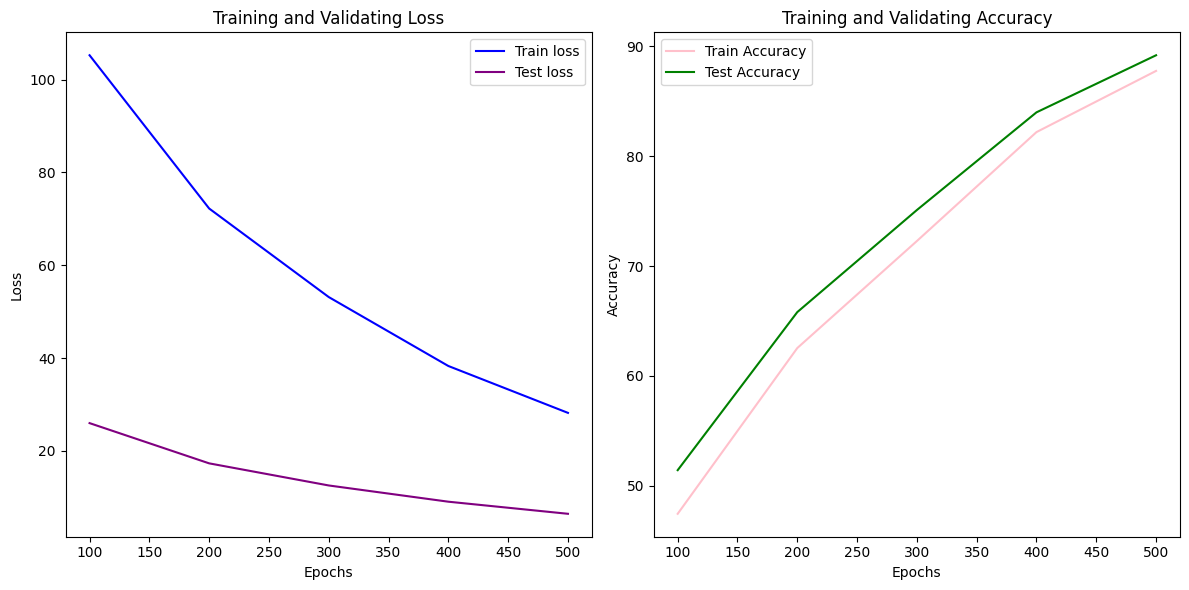

In [26]:
fig, axes = plt.subplots(1, 2, figsize= (12,6))

axes[0].plot(epoch_list, tr_loss_list,color= 'b', label= 'Train loss')
axes[0].plot(epoch_list, te_loss_list, color= 'purple', label= 'Test loss')
axes[0].set_title('Training and Validating Loss')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epoch_list, tr_acc_list, color= 'pink', label= 'Train Accuracy')
axes[1].plot(epoch_list, te_acc_list, color= 'g', label= 'Test Accuracy')
axes[1].set_title('Training and Validating Accuracy')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()



plt.tight_layout()
plt.show()